In [ ]:
!pip -q install kagglehub transformers scikit-learn pandas matplotlib seaborn

In [ ]:
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download(
    "harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows"
)

print("Path to dataset files:", path)

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

100%|██████████| 175k/175k [00:00<00:00, 31.0MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows/versions/1
/root/.cache/kagglehub/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows/versions/1/imdb_top_1000.csv


In [ ]:
import glob

csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

if not csv_files:
    raise FileNotFoundError("No CSV file found in the downloaded dataset.")

# Select the largest CSV file
csv_path = max(csv_files, key=os.path.getsize)

df = pd.read_csv(csv_path, encoding="utf-8-sig")

print("Loaded file:", csv_path)
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Loaded file: /root/.cache/kagglehub/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows/versions/1/imdb_top_1000.csv
Dataset shape: (1000, 16)

Columns:
['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate', 'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director', 'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross']


,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


In [ ]:
# Find columns regardless of capitalization or spaces
column_map = {
    str(col).strip().lower().replace(" ", "_"): col
    for col in df.columns
}

text_candidates = ["overview", "description", "plot", "summary"]
genre_candidates = ["genre", "genres"]

text_col = next(
    (column_map[c] for c in text_candidates if c in column_map),
    None
)

genre_col = next(
    (column_map[c] for c in genre_candidates if c in column_map),
    None
)

if text_col is None or genre_col is None:
    raise ValueError(
        "Could not find the overview and genre columns. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Text column:", text_col)
print("Genre column:", genre_col)

data = df[[text_col, genre_col]].copy()
data.columns = ["text", "genre"]

data = data.dropna()
data["text"] = data["text"].astype(str).str.strip()
data["genre"] = data["genre"].astype(str).str.strip()

data = data[
    (data["text"] != "") &
    (data["genre"] != "")
].copy()

# Use the first genre as the primary genre
data["genre"] = data["genre"].str.split(",").str[0].str.strip()

print("\nNumber of usable examples:", len(data))
print("\nMost common genres:")
print(data["genre"].value_counts().head(15))

Text column: Overview
Genre column: Genre

Number of usable examples: 1000

Most common genres:
genre
Drama        289
Action       172
Comedy       155
Crime        107
Biography     88
Animation     82
Adventure     72
Mystery       12
Horror        11
Western        4
Film-Noir      3
Fantasy        2
Family         2
Thriller       1
Name: count, dtype: int64


In [ ]:
from collections import Counter

MIN_SAMPLES_PER_CLASS = 30
NUM_CLASSES = 5

genre_counts = data["genre"].value_counts()

eligible_genres = genre_counts[
    genre_counts >= MIN_SAMPLES_PER_CLASS
].head(NUM_CLASSES).index.tolist()

if len(eligible_genres) < 2:
    raise ValueError(
        "There are not enough genres with 30 examples each. "
        "Reduce MIN_SAMPLES_PER_CLASS to 10 and rerun this cell."
    )

data = data[data["genre"].isin(eligible_genres)].copy()
data = data.reset_index(drop=True)

# Convert genre names to integer labels
label_names = sorted(data["genre"].unique())

label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for name, i in label2id.items()}

data["label"] = data["genre"].map(label2id).astype(int)

print("Selected genres:", label_names)
print("\nClass distribution:")
print(data["genre"].value_counts())

display(data[["text", "genre", "label"]].head())

Selected genres: ['Action', 'Biography', 'Comedy', 'Crime', 'Drama']

Class distribution:
genre
Drama        289
Action       172
Comedy       155
Crime        107
Biography     88
Name: count, dtype: int64


,text,genre,label
0,Two imprisoned men bond over a number of years...,Drama,4
1,An organized crime dynasty's aging patriarch t...,Crime,3
2,When the menace known as the Joker wreaks havo...,Action,0
3,The early life and career of Vito Corleone in ...,Crime,3
4,A jury holdout attempts to prevent a miscarria...,Crime,3


In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    random_state=42,
    stratify=data["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 567
Validation samples: 122
Testing samples: 122


In [ ]:
import torch
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 96

torch.set_num_threads(2)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Pretrained BERT tokenizer loaded successfully!")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Pretrained BERT tokenizer loaded successfully!


In [ ]:
from datasets import Dataset

train_hf = Dataset.from_pandas(
    train_df[["text", "label"]].reset_index(drop=True)
)

val_hf = Dataset.from_pandas(
    val_df[["text", "label"]].reset_index(drop=True)
)

test_hf = Dataset.from_pandas(
    test_df[["text", "label"]].reset_index(drop=True)
)

def tokenize_data(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

train_hf = train_hf.map(
    tokenize_data,
    batched=True,
    remove_columns=["text"]
)

val_hf = val_hf.map(
    tokenize_data,
    batched=True,
    remove_columns=["text"]
)

test_hf = test_hf.map(
    tokenize_data,
    batched=True,
    remove_columns=["text"]
)

print("Tokenization completed!")
print(train_hf[0].keys())

Map:   0%|          | 0/567 [00:00<?, ? examples/s]

Map:   0%|          | 0/122 [00:00<?, ? examples/s]

Map:   0%|          | 0/122 [00:00<?, ? examples/s]

Tokenization completed!
dict_keys(['label', 'input_ids', 'token_type_ids', 'attention_mask'])


In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
)

# Freeze the pretrained BERT encoder
for param in model.base_model.parameters():
    param.requires_grad = False

# Keep the classification head trainable
for param in model.classifier.parameters():
    param.requires_grad = True

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("BERT loaded successfully on CPU.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameters: 109,486,085
Trainable parameters: 3,845
BERT loaded successfully on CPU.


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation metrics ready!")

Evaluation metrics ready!


In [ ]:
from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

training_args = TrainingArguments(
    output_dir="./bert_genre_results",

    num_train_epochs=2,
    learning_rate=2e-4,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    eval_strategy="epoch",
    save_strategy="no",

    logging_steps=10,
    report_to="none",

    use_cpu=True,
    fp16=False,

    seed=42,
    dataloader_num_workers=0
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_hf,
    eval_dataset=val_hf,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("CPU trainer initialized!")

CPU trainer initialized!


In [ ]:
train_result = trainer.train()

print("\nTraining completed!")
print("Training loss:", train_result.training_loss)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.518110,1.506838,0.401639,0.168431,0.251049,0.187850
2,1.548938,1.482723,0.385246,0.195214,0.223077,0.148026



Training completed!
Training loss: 1.5292926304776904


In [ ]:
test_results = trainer.evaluate(test_hf)

print("\nTest Evaluation Results")
print("-" * 35)

for metric, value in test_results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
1.548938,1.507028,2,0.368852,0.205602,0.215385,0.133759



Test Evaluation Results
-----------------------------------
eval_loss: 1.5070
eval_accuracy: 0.3689
eval_precision: 0.2056
eval_recall: 0.2154
eval_f1: 0.1338


In [ ]:
from sklearn.metrics import classification_report

pred_output = trainer.predict(test_hf)

y_true = pred_output.label_ids
y_pred = np.argmax(pred_output.predictions, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(label_names))),
    target_names=label_names,
    zero_division=0
))

              precision    recall  f1-score   support

      Action       0.67      0.08      0.14        26
   Biography       0.00      0.00      0.00        13
      Comedy       0.00      0.00      0.00        24
       Crime       0.00      0.00      0.00        16
       Drama       0.36      1.00      0.53        43

    accuracy                           0.37       122
   macro avg       0.21      0.22      0.13       122
weighted avg       0.27      0.37      0.22       122



In [ ]:
import torch
import numpy as np
from transformers import AutoModelForSequenceClassification

MODEL_NAME = "bert-base-uncased"

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
)

# Freeze all pretrained parameters
for param in model.base_model.parameters():
    param.requires_grad = False

# Unfreeze the last two Transformer encoder layers
for layer in model.base_model.encoder.layer[-2:]:
    for param in layer.parameters():
        param.requires_grad = True

# Train the classification head
for param in model.classifier.parameters():
    param.requires_grad = True

model.to("cpu")
torch.set_num_threads(2)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("BERT is ready for fine-tuning on CPU.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 14179589
BERT is ready for fine-tuning on CPU.


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.arange(len(label_names))

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].to_numpy()
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)

print("Genres:", label_names)
print("Class weights:", class_weights.tolist())

Genres: ['Action', 'Biography', 'Comedy', 'Crime', 'Drama']
Class weights: [0.9449999928474426, 1.829032301902771, 1.0499999523162842, 1.5119999647140503, 0.5613861680030823]


In [ ]:
import torch.nn as nn
from transformers import Trainer, TrainingArguments

class WeightedTrainer(Trainer):
    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs.pop("labels")
        outputs = model(**inputs)

        loss_fn = nn.CrossEntropyLoss(
            weight=class_weights.to(outputs.logits.device)
        )

        loss = loss_fn(outputs.logits, labels)

        return (loss, outputs) if return_outputs else loss


training_args = TrainingArguments(
    output_dir="./bert_genre_improved",

    num_train_epochs=3,
    learning_rate=2e-5,
    weight_decay=0.01,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,

    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=1,

    logging_steps=10,
    report_to="none",
    use_cpu=True,
    fp16=False,
    seed=42
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_hf,
    eval_dataset=val_hf,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Improved CPU trainer initialized!")

Improved CPU trainer initialized!


In [ ]:
train_result = trainer.train()

print("Improved training completed!")
print("Training loss:", train_result.training_loss)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.551681,1.473076,0.393443,0.536805,0.334254,0.296659
2,1.400948,1.344224,0.540984,0.504633,0.475650,0.467849
3,1.272737,1.318503,0.549180,0.555201,0.480195,0.477033


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Improved training completed!
Training loss: 1.429461116522131


In [ ]:
test_results = trainer.evaluate(test_hf)

print("\nImproved Test Results")
print("-" * 35)

for metric, value in test_results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
1.272737,1.331406,3,0.532787,0.550348,0.512589,0.506058



Improved Test Results
-----------------------------------
eval_loss: 1.3314
eval_accuracy: 0.5328
eval_precision: 0.5503
eval_recall: 0.5126
eval_f1: 0.5061


              precision    recall  f1-score   support

      Action       0.62      0.81      0.70        26
   Biography       0.62      0.38      0.48        13
      Comedy       0.60      0.25      0.35        24
       Crime       0.41      0.56      0.47        16
       Drama       0.50      0.56      0.53        43

    accuracy                           0.53       122
   macro avg       0.55      0.51      0.51       122
weighted avg       0.55      0.53      0.52       122



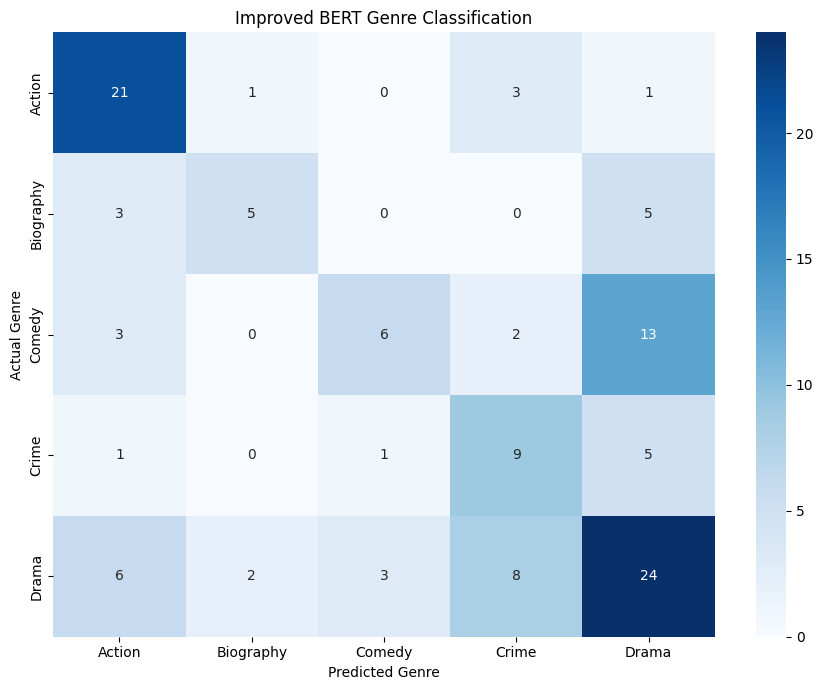

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

pred_output = trainer.predict(test_hf)

y_true = pred_output.label_ids
y_pred = np.argmax(pred_output.predictions, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(label_names))),
    target_names=label_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(label_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names
)

plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.title("Improved BERT Genre Classification")
plt.tight_layout()
plt.show()

In [ ]:
def predict_genre(text):
    model.eval()

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)[0]

    predicted_id = probabilities.argmax().item()

    print("Movie overview:", text)
    print("Predicted genre:", id2label[predicted_id])
    print(f"Model confidence: {probabilities[predicted_id].item():.2%}")

    return id2label[predicted_id]

predict_genre(
    "A detective investigates a mysterious murder and discovers "
    "a dangerous conspiracy involving several powerful people."
)

Movie overview: A detective investigates a mysterious murder and discovers a dangerous conspiracy involving several powerful people.
Predicted genre: Action
Model confidence: 32.92%


'Action'